# Accuracy, stability, and energy decay for 1D Allen–Cahn

**MATH 6201 · Study reference.** Run cells in order with Python 3.10+ and NumPy, SciPy, and Matplotlib installed. Keep `allen_cahn.py` beside the notebook. The last cell saves a single US Letter figure sheet to the working folder. The course asks for your own code: use this notebook to understand, independently implement, and check the method you submit.

We solve $u_t=\varepsilon^2u_{xx}+u-u^3$ on $[0,1)$ with periodic boundaries. Here $\varepsilon$ controls interface thickness. We use $h=1/N$, nodes $x_j=jh$, and indices modulo $N$, so $x=1$ is never stored twice.

Let $D_h$ denote the centered second difference, $L=\varepsilon^2D_h$, $R(U)=U-U^3$ componentwise, and $F^n$ the optional forcing. The two updates are

$$U^{n+1}=U^n+\Delta t\,[LU^n+R(U^n)+F^n],$$
$$ (I-\Delta t L)U^{n+1}=U^n+\Delta t\,[R(U^n)+F^n].$$

The second equation uses one linear solve per **full** time step. Sparse LU is set up once per run, because the matrix is constant for fixed $N,\varepsilon,\Delta t$. An integer step count makes comparisons at the same final time possible; tables use the actual step size $T/n_{\rm steps}$.

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter

from allen_cahn import (
    grid, periodic_laplacian, reaction, discrete_energy, l2_error,
    evolve, exact_uniform, manufactured, manufactured_source,
    diffusion_and_reaction_limits, energy_rises,
)

METHODS = ("explicit", "semi-implicit")
COLORS = {"explicit": "#a13c15", "semi-implicit": "#174e89"}
MARKERS = {"explicit": "o", "semi-implicit": "s"}
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.24,
                     "svg.fonttype": "none"})

def print_orders(label, sizes, errors):
    sizes, errors = np.asarray(sizes), np.asarray(errors)
    orders = np.log(errors[:-1] / errors[1:]) / np.log(sizes[:-1] / sizes[1:])
    print(f"{label:>12} {'error':>13} {'order':>8}")
    for size, error, order in zip(sizes, errors, np.r_[np.nan, orders]):
        tag = f"{order:.3f}" if np.isfinite(order) else "—"
        print(f"{size:12.5g} {error:13.5e} {tag:>8}")
    return orders

## 1 · Verifying the stencil and the constant equilibriam

A periodic stencil must send constants to zero and couple the first and last entries. The two constant phases $u=\pm 1$ are exact equilibria because the reaction also vanishes there. A nonconstant linear-mode check below will complement this test; equilibrium preservation alone cannot detect an incorrect stencil with zero row sums.


In [8]:
n, eps, T = 32, 0.08, 0.25
x, h = grid(n)
D = periodic_laplacian(n)
assert D.nnz == 3*n
assert D[0, -1] == D[-1, 0] == 1/h**2
np.testing.assert_allclose(D @ np.ones(n), 0, atol=1e-12)
mode = np.sin(2*np.pi*x)
lam = -4*np.sin(np.pi/n)**2/h**2
np.testing.assert_allclose(D @ mode, lam*mode, atol=1e-10)
for method in METHODS:
    for phase in (-1.0, 1.0):
        run = evolve(np.full(n, phase), eps, T, 32, method, record_energy=True)
        drift = np.max(np.abs(run.u - phase))
        print(f"{method:>13} | u={phase:+g} | max drift {drift:.3e} | "
              f"max energy {max(run.energies):.3e}")
        assert run.completed and not run.escaped and drift < 1e-12

     explicit | u=-1 | max drift 0.000e+00 | max energy 0.000e+00
     explicit | u=+1 | max drift 0.000e+00 | max energy 0.000e+00
semi-implicit | u=-1 | max drift 1.776e-15 | max energy 1.294e-30
semi-implicit | u=+1 | max drift 1.776e-15 | max energy 1.294e-30


## 2 · Test time stepping against an exact uniform solution

When $u$ is spatially constant, $D_h U=0$ and both updates reduce to Euler for $u'=u-u^3$. For $u(0)=a$, $u^2$ satisfies a logistic equation. Restoring the sign of $a$ gives
$$u(t)=a\big[a^2+(1-a^2)e^{-2t}\big]^{-1/2}.$$
This verifies reaction and time integration in the uniform limit; the manufactured test next exercises diffusion on a nonconstant solution.

In [9]:
uniform_counts = np.array([16, 32, 64, 128, 256])
uniform_T, a = 1.0, 0.35
uniform_steps = uniform_T / uniform_counts
uniform_errors = {}
for method in METHODS:
    uniform_errors[method] = [
        l2_error(evolve(np.full(8, a), 0.04, uniform_T, int(k), method).u,
                 exact_uniform(a, uniform_T)) for k in uniform_counts
    ]
    print("\nUniform ODE:", method)
    p = print_orders("dt", uniform_steps, uniform_errors[method])
    assert 0.9 < p[-1] < 1.1


Uniform ODE: explicit
          dt         error    order
      0.0625   1.59973e-03        —
     0.03125   7.63766e-04    1.067
    0.015625   3.72929e-04    1.034
   0.0078125   1.84235e-04    1.017
   0.0039062   9.15611e-05    1.009

Uniform ODE: semi-implicit
          dt         error    order
      0.0625   1.59973e-03        —
     0.03125   7.63766e-04    1.067
    0.015625   3.72929e-04    1.034
   0.0078125   1.84235e-04    1.017
   0.0039062   9.15611e-05    1.009


## 3 · Separate spatial and temporal convergence with a manufactured solution

Prescribe $w(x,t)=0.4e^{-t}\sin(2\pi x)$, then set $F=w_t-\varepsilon^2w_{xx}-R(w)$. We know $w_t=-w$ and $w_{xx}=-(2\pi)^2w$.

- **Space:** use the analytic forcing on four grids at the same fine time step. Halve the step on the finest grid to check that residual temporal error is small relative to the measured spatial error.
- **Time:** on one fixed grid, use $F_h=w_t-\varepsilon^2D_hw-R(w)$ instead. Then sampled $w$ is the exact solution of the forced **grid ODE**, eliminating the spatial error floor. This tests both time updates on nonconstant data, including the implicit diffusion term. It is not a separate test of the spatial stencil.

The reported error is $\sqrt{h\sum_j |U_j-w_j|^2}$. Observed order is the log error ratio divided by the log step-size ratio. The energy decay test applies only to **unforced** runs.

In [3]:
mms_eps, mms_T = 0.08, 0.125
space_ns = np.array([16, 32, 64, 128])
space_h = 1/space_ns
space_count = 16384
space_errors = {}
for method in METHODS:
    errors = []
    for ni in space_ns:
        x, _ = grid(int(ni))
        src = manufactured_source(x, mms_eps)
        run = evolve(manufactured(x, 0), mms_eps, mms_T, space_count, method, src)
        assert run.completed and not run.escaped
        errors.append(l2_error(run.u, manufactured(x, mms_T)))
    space_errors[method] = errors
    print("\nManufactured space:", method)
    p = print_orders("h", space_h, errors)
    fine = evolve(manufactured(x, 0), mms_eps, mms_T, 2*space_count, method, src)
    time_effect = l2_error(run.u, fine.u) / errors[-1]
    print(f"Finest grid: halving dt changes U by {time_effect:.2%} of its error.")
    assert 1.8 < p[-1] < 2.2 and time_effect < 0.10

time_counts = np.array([16, 32, 64, 128, 256])
time_dt = mms_T/time_counts
x, _ = grid(32)
src = manufactured_source(x, mms_eps, laplacian=periodic_laplacian(len(x)))
time_errors = {}
for method in METHODS:
    time_errors[method] = [
        l2_error(evolve(manufactured(x, 0), mms_eps, mms_T, int(k), method, src).u,
                 manufactured(x, mms_T)) for k in time_counts
    ]
    print("\nManufactured time:", method)
    p = print_orders("dt", time_dt, time_errors[method])
    assert 0.9 < p[-1] < 1.1


Manufactured space: explicit
           h         error    order
      0.0625   1.10339e-04        —
     0.03125   2.75894e-05    2.000
    0.015625   6.80595e-06    2.019
   0.0078125   1.60407e-06    2.085
Finest grid: halving dt changes U by 4.07% of its error.

Manufactured space: semi-implicit
           h         error    order
      0.0625   1.10404e-04        —
     0.03125   2.76551e-05    1.997
    0.015625   6.87179e-06    2.009
   0.0078125   1.66996e-06    2.041
Finest grid: halving dt changes U by 1.93% of its error.

Manufactured time: explicit
          dt         error    order
   0.0078125   1.33488e-04        —
   0.0039062   6.67631e-05    1.000
   0.0019531   3.33863e-05    1.000
  0.00097656   1.66943e-05    1.000
  0.00048828   8.34747e-06    1.000

Manufactured time: semi-implicit
          dt         error    order
   0.0078125   6.62034e-05        —
   0.0039062   3.31227e-05    0.999
   0.0019531   1.65666e-05    1.000
  0.00097656   8.28463e-06    1.000
  

## 4 · Predict and probe a linear stability limit

For a Fourier mode of the periodic grid, define $q_k=4\varepsilon^2h^{-2}\sin^2(\pi k/N)\ge 0$. The diffusion eigenvalue is $-q_k$. At $u=\pm 1$, $R'(u)=-2$, so the two amplification factors for perturbations are
$$G_{\rm E}=1-\Delta t(q_k+2),\qquad
G_{\rm SI}=\frac{1-2\Delta t}{1+\Delta t q_k}.$$
Requiring $|G|\le 1$ for every mode gives the explicit bound $2/(q_{\max}+2)$, slightly stricter than the diffusion-only bound $2/q_{\max}=h^2/(2\varepsilon^2)$ for even $N$. For semi-implicit Euler the denominator damps diffusion, but $k=0$ still gives the local reaction limit $\Delta t\le 1$ for all modes about these equilibria. Linear neutrality at equality is not a guarantee for the nonlinear problem. These are local Fourier statements; linearization near $u=0$ has genuine physical growth in low modes.

We seed the highest Fourier mode around $u=1$ and measure its amplitude ratio after one step. Separately we seed a **uniform** perturbation to show where implicit diffusion cannot help.

In [11]:
probe_n, probe_eps = 64, 0.04
diff_bound, lin_bound = diffusion_and_reaction_limits(probe_n, probe_eps)
qmax = 2/diff_bound
print(f"Diffusion-only dt limit {diff_bound:.6g}; with reaction {lin_bound:.6g}")
checker = (-1.0)**np.arange(probe_n)
amplitude = 1e-6
probe_ratios = np.array([0.5, 0.8, 0.95, 1.0, 1.05, 1.2, 1.4])
probe_values = {}
for method in METHODS:
    observed = []
    for dt in probe_ratios * lin_bound:
        run = evolve(1 + amplitude*checker, probe_eps, dt, 1, method)
        observed.append(abs(np.mean((run.u-1)*checker)/amplitude))
    theory = (1 - probe_ratios*lin_bound*(qmax+2) if method == "explicit"
              else (1-2*probe_ratios*lin_bound)/(1+probe_ratios*lin_bound*qmax))
    probe_values[method] = np.asarray(observed)
    np.testing.assert_allclose(observed, np.abs(theory), atol=2e-8)
    print(method, "one-step |G|:", np.round(observed, 4))

print("\nUniform reaction perturbation: semi-implicit Euler")
for dt in (0.5, 1.2):
    run = evolve(np.full(probe_n, 1 + amplitude), probe_eps, 10*dt, 10,
                 "semi-implicit", record_energy=True)
    growth = abs(run.u.mean()-1)/amplitude
    print(f"dt={dt:.2f} | final / initial perturbation {growth:.4g} | "
          f"energy rises {energy_rises(run.energies)}/10")

Diffusion-only dt limit 0.0762939; with reaction 0.0708858
explicit one-step |G|: [0.  0.6 0.9 1.  1.1 1.4 1.8]
semi-implicit one-step |G|: [0.4816 0.3565 0.3129 0.3003 0.2884 0.2569 0.2226]

Uniform reaction perturbation: semi-implicit Euler
dt=0.50 | final / initial perturbation 0 | energy rises 0/10
dt=1.20 | final / initial perturbation 28.92 | energy rises 9/10


## 5 · Nonlinear time-step and interface-width study

Using the same smooth initial profile $0.85\sin(2\pi x)+0.10\cos(4\pi x)$, with a $10^{-6}$ highest-mode probe added in the **time-step sweep** so growth of the shortest grid wave has a reproducible seed. Using three values of $\varepsilon$ and a fixed even grid. Comparing each run to a refined **same-grid** time reference at the same final time, so this measures time error rather than total PDE error. Comparing two reference time steps and use a separate smooth, unseeded $N$ versus $2N$ comparison to assess spatial sensitivity without defining the seed differently on the two grids.

Reporting three separate outcomes: final $L^2$ error, any crossing of $|u|>2$ (a finite-time warning), and energy increases. A numerical overflow or $|u|>10$ stops a run. A run can be bounded and still have large error or energy growth; a bounded observation is not a proof of stability. Report energy increases only above the tolerance in `energy_rises`. The edge gradient $(U_{j+1}-U_j)/h$ is paired with $D_h$ because $D_h=-G^TG$. Thus the discrete energy is $h\sum_j [\varepsilon^2(GU)_j^2/2+(U_j^2-1)^2/4]$, the energy for the semidiscrete gradient flow.

In [12]:
N, final_time = 256, 1.2
EPSILONS = (0.02, 0.04, 0.08)
x, h = grid(N)

def initial_profile(x):
    return 0.85*np.sin(2*np.pi*x) + 0.10*np.cos(4*np.pi*x)

initial = initial_profile(x) + 1e-6*(-1.0)**np.arange(N)
reference_counts = 8192
rows, resolution = [], []
for eps in EPSILONS:
    diff_dt, bound = diffusion_and_reaction_limits(N, eps)
    fine = evolve(initial, eps, final_time, reference_counts, "semi-implicit")
    finer = evolve(initial, eps, final_time, 2*reference_counts, "semi-implicit")
    assert fine.completed and finer.completed and not (fine.escaped or finer.escaped)
    ref_gap = l2_error(fine.u, finer.u)
    x2, _ = grid(2*N)
    smooth_n = evolve(initial_profile(x), eps, final_time, reference_counts, "semi-implicit")
    smooth_2n = evolve(initial_profile(x2), eps, final_time, reference_counts, "semi-implicit")
    mesh_gap = l2_error(smooth_n.u, smooth_2n.u[::2])
    resolution.append((eps, eps/h, diff_dt, bound, ref_gap, mesh_gap))
    targets = list(bound*np.array([.25, .5, .8, .98, 1.02, 1.2, 2, 4, 8]))
    targets += [0.10, 0.25, 0.50, 1.20]
    counts = sorted({max(1, round(final_time/dt)) for dt in targets}, reverse=True)
    for method in METHODS:
        for k in counts:
            run = evolve(initial, eps, final_time, k, method, record_energy=True)
            error = l2_error(run.u, finer.u) if run.completed else np.nan
            rows.append(dict(eps=eps, method=method, dt=run.dt, ratio=run.dt/bound,
                             error=error, rises=energy_rises(run.energies),
                             peak=run.peak, completed=run.completed, escaped=run.escaped))

print(" eps    eps/h     diffusion dt   + reaction dt    ref L2 change    N vs 2N L2")
for eps, width, d, b, rg, mg in resolution:
    print(f"{eps:.3f}   {width:6.2f}    {d:12.5g}   {b:13.5g}   {rg:13.3e}   {mg:11.3e}")
print("\n eps     method            dt     dt/bound    final L2     E rises   max|u|   status")
for r in rows:
    status = ("stopped" if not r["completed"] else "escaped" if r["escaped"] else "bounded")
    print(f"{r['eps']:.3f}    {r['method']:>13}   {r['dt']:9.4g}    {r['ratio']:8.3f}"
          f"    {r['error']:10.3e}   {r['rises']:5d}    {r['peak']:8.3g}   {status}")

 eps    eps/h     diffusion dt   + reaction dt    ref L2 change    N vs 2N L2
0.020     5.12        0.019073        0.018716       4.693e-06     1.574e-05
0.040    10.24       0.0047684       0.0047457       3.596e-06     2.370e-05
0.080    20.48       0.0011921       0.0011907       2.423e-06     1.860e-05

 eps     method            dt     dt/bound    final L2     E rises   max|u|   status
0.020         explicit    0.004687       0.250     2.100e-04       0       0.993   bounded
0.020         explicit    0.009375       0.501     4.246e-04       0       0.993   bounded
0.020         explicit       0.015       0.801     6.832e-04       0       0.993   bounded
0.020         explicit     0.01846       0.986     8.427e-04       0       0.993   bounded
0.020         explicit     0.01905       1.018     8.698e-04       0       0.993   bounded
0.020         explicit     0.02264       1.210           nan      19        11.6   stopped
0.020         explicit      0.0375       2.004           na

## 6 · Representating energy histories and solution profiles

Compare both methods at the same actual steps below and above the equilibrium linear bound for explicit Euler. A stopped run contributes data only through its last finite step. In the profile panel we use a fine, stable semi-implicit step and close the periodic curve by plotting the first value again at $x=1$.

In [13]:
illustration_eps = 0.04
_, bound = diffusion_and_reaction_limits(N, illustration_eps)
energy_examples = {}
for method in METHODS:
    for label, factor in (("below", 0.7), ("above", 1.3)):
        k = round(final_time/(factor*bound))
        run = evolve(initial, illustration_eps, final_time, k, method, record_energy=True)
        energy_examples[method, label] = run
        print(f"{method:>13}, {label}: dt/dt_lin={run.dt/bound:.3f}, "
              f"energy rises={energy_rises(run.energies)}, reached t={run.t:.3g}, "
              f"escaped={run.escaped}")
profiles = evolve(initial_profile(x), illustration_eps, final_time, 4096, "semi-implicit",
                  snapshot_steps=(0, 1024, 2048, 4096))

     explicit, below: dt/dt_lin=0.700, energy rises=0, reached t=1.2, escaped=False
     explicit, above: dt/dt_lin=1.297, energy rises=19, reached t=0.215, escaped=True
semi-implicit, below: dt/dt_lin=0.700, energy rises=0, reached t=1.2, escaped=False
semi-implicit, above: dt/dt_lin=1.297, energy rises=0, reached t=1.2, escaped=False


## 7 · Exporting one page of figures

The report sheet includes the two convergence checks, the mode test, nonlinear time errors at three $\varepsilon$ values, representative energy histories, and profiles. The printed tables retain the details that would overcrowd the figure. The error panel omits escaped and stopped runs from its curves and marks those trials at the top, without assigning them a numerical error there.

Saved C:\Users\wasif\Documents\Codex\2026-10-05\g\outputs\allen_cahn_report_figures.svg
Saved C:\Users\wasif\Documents\Codex\2026-10-05\g\outputs\allen_cahn_report_figures.png


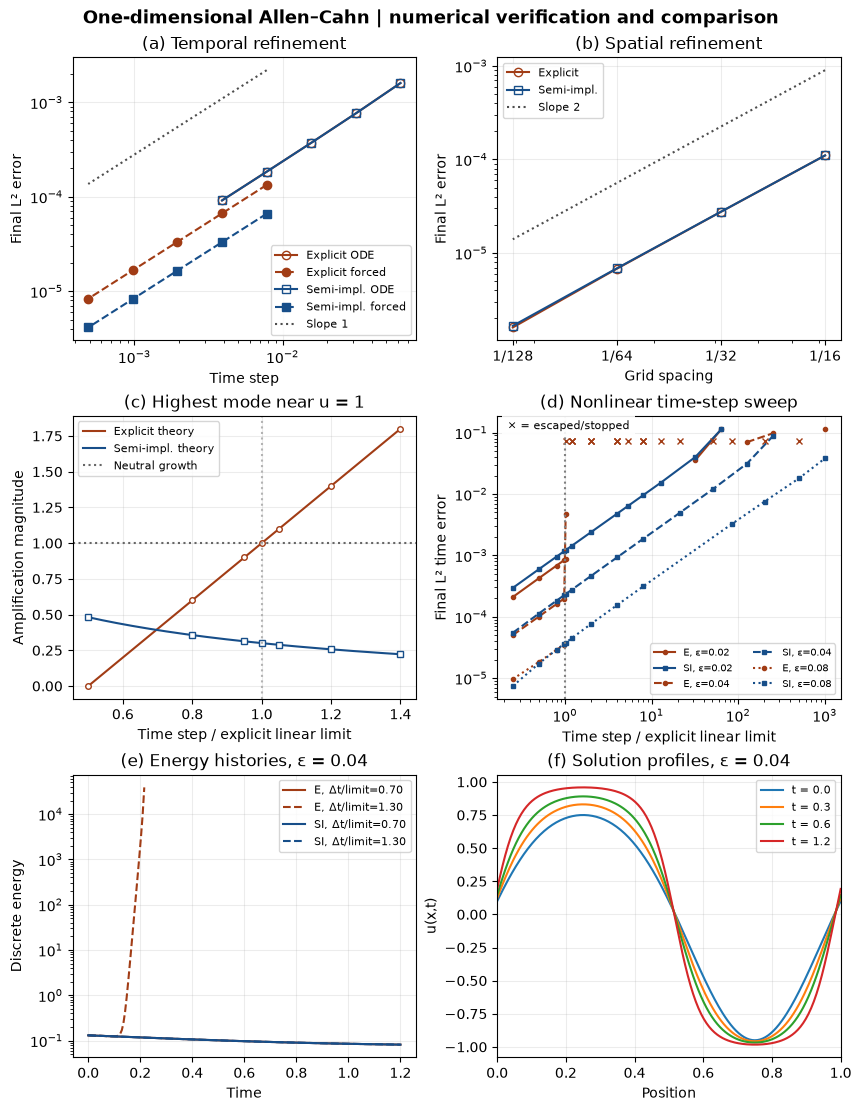

In [14]:
fig, ax = plt.subplots(3, 2, figsize=(8.5, 11), layout="constrained")
fig.suptitle("One-dimensional Allen–Cahn | numerical verification and comparison",
             fontsize=13, fontweight="bold")

a0, a1, a2, a3, a4, a5 = ax.flat
for method in METHODS:
    color, marker = COLORS[method], MARKERS[method]
    short = "Explicit" if method == "explicit" else "Semi-impl."
    a0.loglog(uniform_steps, uniform_errors[method], marker+"-", color=color,
              markerfacecolor="none", label=short+" ODE")
    a0.loglog(time_dt, time_errors[method], marker+"--", color=color, label=short+" forced")
    a1.loglog(space_h, space_errors[method], marker+"-", color=color,
              markerfacecolor="none", label=short)
    d = np.linspace(probe_ratios.min(), probe_ratios.max(), 200)
    g = (1-d*lin_bound*(qmax+2) if method == "explicit"
         else (1-2*d*lin_bound)/(1+d*lin_bound*qmax))
    a2.plot(d, abs(g), "-", color=color, label=short+" theory")
    a2.plot(probe_ratios, probe_values[method], marker, ms=4, mfc="white", color=color)
a0.loglog(time_dt, 0.28*time_dt, ":", color="0.3", label="Slope 1")
a1.loglog(space_h, 0.23*space_h**2, ":", color="0.3", label="Slope 2")
a0.set(title="(a) Temporal refinement", xlabel="Time step", ylabel="Final L² error")
a1.set(title="(b) Spatial refinement", xlabel="Grid spacing", ylabel="Final L² error")
a1.set_xticks(space_h[::-1], labels=[f"1/{n}" for n in space_ns[::-1]])
a1.xaxis.set_minor_formatter(NullFormatter())
a2.axhline(1, color="0.4", ls=":", label="Neutral growth")
a2.axvline(1, color="0.7", ls=":")
a2.set(title="(c) Highest mode near u = 1", xlabel="Time step / explicit linear limit",
       ylabel="Amplification magnitude")

for eps, style in zip(EPSILONS, ("-", "--", ":")):
    for method in METHODS:
        color, marker = COLORS[method], MARKERS[method]
        selected = [r for r in rows if r["eps"] == eps and r["method"] == method]
        short = "E" if method == "explicit" else "SI"
        a3.loglog([r["ratio"] for r in selected],
                  [r["error"] if not r["escaped"] and r["completed"] else np.nan
                   for r in selected], marker=marker, ls=style, color=color, ms=3,
                  label=f"{short}, ε={eps:g}")
        flagged = [r["ratio"] for r in selected if r["escaped"] or not r["completed"]]
        a3.plot(flagged, [0.91 if method == "explicit" else 0.85]*len(flagged),
                "x", color=color, ms=4, transform=a3.get_xaxis_transform())
a3.axvline(1, color="0.5", ls=":")
a3.set(title="(d) Nonlinear time-step sweep",
       xlabel="Time step / explicit linear limit", ylabel="Final L² time error")
a3.text(.03, .985, "× = escaped/stopped", va="top", transform=a3.transAxes, fontsize=8,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})

for (method, label), run in energy_examples.items():
    short = "E" if method == "explicit" else "SI"
    a4.semilogy(run.times, run.energies, color=COLORS[method],
                ls="-" if label == "below" else "--",
                label=f"{short}, Δt/limit={run.dt/bound:.2f}")
a4.set(title="(e) Energy histories, ε = 0.04", xlabel="Time", ylabel="Discrete energy")
for t, state in profiles.snapshots.items():
    a5.plot(np.r_[x, 1], np.r_[state, state[0]], label=f"t = {t:.1f}")
a5.set(title="(f) Solution profiles, ε = 0.04", xlabel="Position", ylabel="u(x,t)",
       xlim=(0, 1))
for axis in (a0, a1, a2, a4, a5):
    axis.legend(fontsize=8, loc="best")
a3.legend(fontsize=7.5, ncol=2, loc="lower right")
for ext in ("svg", "png"):
    destination = Path(f"allen_cahn_report_figures.{ext}")
    fig.savefig(destination, dpi=240)
    print(f"Saved {destination.resolve()}")
plt.show()